# Урок 11. Почему дальняя перекладина занимает меньше пикселей

[Программа курса](../../README_ru.md)

На прошлом рисунке камера знала, что вершина находится на метр правее и на четыре метра впереди. Этого ещё мало для фотографии. Нужен адрес внутри кадра. Проведём через точку луч, положим поперёк луча маленькую сетку и посмотрим, на какое деление он попадёт.

In [1]:
%matplotlib inline
from pathlib import Path
import sys

course = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "geometry3d.py").is_file())
if str(course) not in sys.path:
    sys.path.insert(0, str(course))

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
import geometry3d as geo
import geometry_demos as demos
np.set_printoptions(precision=4, suppress=True)

## 1. Один метр на разных расстояниях

Синяя перекладина длиной ровно метр лежит на высоте $y=0.5$ м ниже оптической оси. Слева вид сверху. Лучи от камеры идут к середине и краям перекладины. Справа кадр из 201 столбца и 121 строки. При глубине 4 м и фокусе 80 пикселей перекладина занимает 20 пиксельных интервалов. На глубине 2 м их будет 40. При одинаковом фокусе результат меняет само отношение ширины к глубине.

Зелёная линия слева находится в 0.2 м перед камерой. Когда камера доезжает почти до объекта, перекладина сначала уходит за края кадра, а затем целиком отсекается по глубине. У этих двух исчезновений разные причины, и ниже можно проследить оба по числам.

In [2]:
display(demos.geometry_lab(11, "ru"))

Фиолетовая перекладина тоже длиной в метр, только её глубина в мире всегда 8 м. Она поднята на полметра над оптической осью, поэтому в кадре находится выше синей. Это второй предмет в одном кадре. Он помогает поставить опыт, где по синей перекладине две настройки камеры выглядят совершенно одинаково. Дальний предмет их различит.

## 2. Что здесь называется глубиной

Предыдущий урок оставил вершину в системе камеры. У неё есть смещение от объектива и длина этого смещения. Почему же для масштаба картинки пригодится только третье число? Один конец синей перекладины находится в $(0.5,0.5,4)$ м, второй в $(1.5,0.5,4)$ м. Расстояния от начала до них равны соответственно $\sqrt{0.25+0.25+16}\approx4.06$ м и $\sqrt{2.25+0.25+16}\approx4.30$ м. Однако оба конца лежат на одной плоскости, в четырёх метрах **вперёд** от камеры. Для пересечения лучей с другой плоскостью, параллельной первой, важно движение вперёд. Обе точки получат один и тот же коэффициент уменьшения.

У реального фотоаппарата свет, прошедший через маленькое отверстие, попадает на сенсор позади него, и изображение перевёрнуто. Для расчёта поставим перед отверстием воображаемую плоскость. Она пересекает те же прямые с той стороны, где расположен предмет. Тогда правый край предмета даёт правый край изображения, положительный $y$ по-прежнему даёт движение вниз. В расчёте уже учтён этот выбор стороны. Дополнительный минус перед $x$ перевернул бы весь кадр.

## 3. Где луч проткнёт плоскость

Начало луча — центр камеры $(0,0,0)$. Середина перекладины находится в $P=(1,0.5,4)$ м. По дороге от камеры к точке расстояния по всем трём осям растут в одинаковое число раз. На четверти пути выходит $(1/4,0.5/4,4/4)=(0.25,0.125,1)$ м. Последнее число стало 1. Это пересечение с условной плоскостью, поставленной в метре перед камерой. Удвоенная точка $(2,1,8)$ встретит эту плоскость ровно там же. Один пиксель оставляет целый луч возможных глубин.

В общем виде точка камеры записывается $(x,y,z)$. Чтобы довести последний компонент до 1, все три компонента делятся на $z$. На плоскости остаются $x/z$ и $y/z$. Это отношения метров к метрам, они безразмерны. Для далёкой точки тот же метр поперёк занимает меньшую долю глубины. Деление работает для $z>0$; на нуле у луча нет конечной точки пересечения в общем случае. За камерой, при $z<0$, продолжение прямой уже смотрит в противоположную сторону.

In [3]:
p = np.array([1., .5, 4.])
print("P / z =", p/p[2], "    2P / (2z) =", (2*p)/(2*p[2]))
assert np.allclose(p[:2]/p[2], (2*p)[:2]/(2*p[2]))

P / z = [0.25  0.125 1.   ]     2P / (2z) = [0.25  0.125 1.   ]


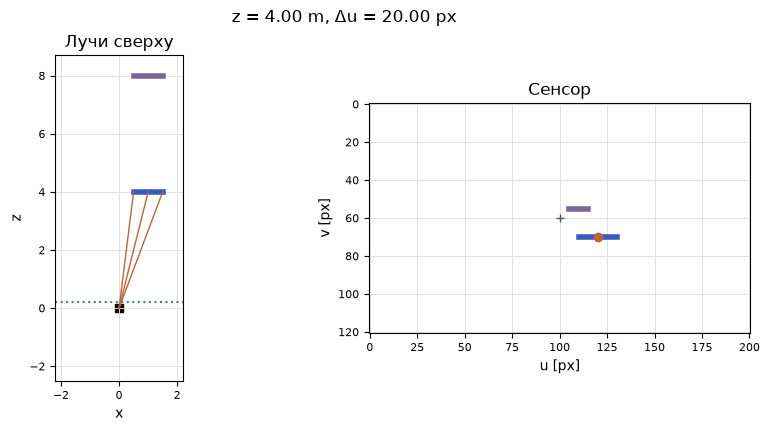

In [4]:
fig = demos.perspective_figure("ru")
plt.show()

## 4. Как в числитель попали пиксели

Для начала допустим, что картину принимает крошечная плёнка. Плоскость стоит на расстоянии 4 мм от отверстия. Середина перекладины имеет отношение $x/z=1/4$. Луч уйдёт от середины плёнки на $4\cdot1/4=1$ мм. Отверстие, перекладина и её луч образовали два подобных треугольника: чтобы перейти от четырёх метров глубины к четырём миллиметрам, и боковую сторону пришлось уменьшить в тысячу раз. Точка предмета была на метр правее, а на плёнке оказался всего миллиметр.

Пусть в одном миллиметре умещаются 20 шагов пиксельной сетки. Один шаг по горизонтали равен $1/20=0.05$ мм. Полученный миллиметр занимает $1/0.05=20$ шагов. Точно такой же результат получится, если заранее поделить расстояние от отверстия до плёнки на шаг сетки: $4/0.05=80$. Так появляется **фокус в пикселях** $f_x=80$ px. Его физической длине соответствует 4 мм только при названном размере пикселя. Из одних «80 пикселей» узнать миллиметры объектива нельзя.

Вертикальную сетку можно нанести гуще. При шаге 0.04 мм тот же объектив даст $f_y=4/0.04=100$ px. Так как $y/z=0.5/4=0.125$, смещение составит $100\cdot0.125=12.5$ пикселя вниз. Половина пикселя допустима: луч проходит через непрерывную плоскость. Только запись в массив требует целого номера строки. Для гауссианы оставим дробную часть центра, чтобы соседние пиксели получили разные веса вокруг настоящей позиции. Округление центра до вычисления весов заставляло бы движущееся пятно перескакивать по целым делениям.

## 5. От долей до адреса пикселя

Мы измерили направление. Теперь нужна шкала. Фокус $f_x=80$ пикселей означает, что единице $x/z$ соответствует 80 пиксельных интервалов по горизонтали. В этом опыте $f_y=80$ и по вертикали. Например, $x/z=0.25$ даёт $80\cdot0.25=20$ пикселей вправо от оптической оси. Нижнее смещение $80\cdot0.125=10$ пикселей.

У изображения ширины $W=201$ центры столбцов имеют номера от 0 до 200, поэтому центральный номер $c_x=(W-1)/2=100$. Высота $H=121$ даёт $c_y=60$. Эта пара — главная точка, адрес пересечения оптической оси с кадром. В реальной калибровке её положение оценивается отдельно и может сместиться. Центры пикселей занимают целые координаты, но геометрическое пересечение луча бывает и между ними. Округление до ближайшего адреса меняет задачу, поэтому координаты пока остаются дробными.

$$
\begin{aligned}
u&=c_x+f_x\,x/z=100+80\cdot1/4=120,\\
v&=c_y+f_y\,y/z=60+80\cdot0.5/4=70.
\end{aligned}
$$

Здесь $u$ отсчитывается вправо, $v$ вниз. У левого края перекладины $x=0.5$, откуда $u=110$. У правого $x=1.5$ и $u=130$. Разность концов $130-110=20$ даёт длину в пиксельных интервалах. Если закрасить все целые центры вместе с обоими концами, их окажется 21. Длина линии и число затронутых центров отвечают на разные вопросы.

In [5]:
principal = (100, 60)
for x in [.5, 1, 1.5]:
    print(f"x={x:g} m →", geo.project_point([x,.5,4], 80, principal, near=.2), "px")
np.testing.assert_allclose(geo.project_point(p, (80,100), principal), [120,72.5])

x=0.5 m → [110.  70.] px
x=1 m → [120.  70.] px
x=1.5 m → [130.  70.] px


## 6. Кадр можно обрезать, не двигая камеру

В исходном кадре центр оптической оси приходится на $(100,60)$. Это **главная точка**, место, куда проектируется луч $(0,0,1)$. Обрежем слева 30 столбцов и сверху 10 строк. Камера осталась на месте, значит, лучи в мире не изменились. Новый столбец с номером 0 был прежним столбцом 30. Поэтому у каждого старого адреса надо вычесть $(30,10)$. Середина перекладины была в $(120,70)$, станет в $(90,60)$. Главная точка тоже переедет, в $(70,50)$. Разность $(90-70,60-50)=(20,10)$ останется прежней. Фокус в пикселях при такой обрезке вообще не меняется.

С изменением разрешения иначе. Для простого примера из исходной сетки оставим только чётные строки и столбцы, начиная с нулевых. Старый столбец 120 станет столбцом 60, а столбец 100 станет столбцом 50. Разность теперь всего 10. На новом кадре шаг сетки вдвое крупнее, поэтому и числа $f_x,f_y$ делятся на два. Проверка для нашей точки даёт $u'=50+40\cdot1/4=60$ и $v'=30+40\cdot0.5/4=35$. Это правило выведено для конкретной привязки пиксельных центров. Если программа пересчёта изображения совмещает края пикселей, а не центры чётных столбцов, возникает поправка на долю пикселя. Надёжный способ вывести новые параметры — узнать, куда реально перешли два известных адреса.

В тренировке камера может быть калибрована на больших оригиналах, а изображения уменьшены ради скорости. Если уменьшить кадры вдвое и оставить в камере прежний фокус, пятно с ненулевым $x$ окажется слишком далеко от новой главной точки. Пятно на оси не выдаст ошибки: что при старом, что при новом фокусе множитель перед $x$ умножается на ноль. По краям кадра смещение становится заметнее. Случай с одним пятном точно по центру — слишком мягкая проверка калибровки.

Теперь можно буквально измерить, сколько сцены помещается в кадр. От главной точки до центра крайнего правого пикселя исходного кадра ровно 100 интервалов. При $f_x=80$ наклон крайнего луча равен $x/z=100/80=1.25$. В плоскости на глубине 4 м он проходит через $x=5$ м. Левый край симметричен, так что между центрами крайних пикселей помещается 10 м стены. С тем же сенсором и $f_x=160$ остаётся 5 м. А после выборки каждого второго пикселя одновременно вдвое уменьшаются и расстояние до крайнего центра, и фокус в пикселях. Отношение $50/40$ по-прежнему равно $1.25$. Сцена та же, только измерений на ней вдвое меньше по горизонтали.

In [6]:
p = np.array([1., .5, 4.])
uv = geo.project_point(p, 80, (100,60))
print("original", uv, " crop", uv-[30,10], " half", uv/2)
np.testing.assert_allclose(geo.project_point(p,80,(70,50)), uv-[30,10])
np.testing.assert_allclose(geo.project_point(p,40,(50,30)), uv/2)
np.testing.assert_allclose(geo.project_point(p,(80,100),(100,60)), [120,72.5])

original [120.  70.]  crop [90. 60.]  half [60. 35.]


## 7. Та же запись в виде матрицы

Для двух фокусов и главной точки удобно держать одну матрицу $K$. В верхней строке сначала умножаются $f_x x$ и $c_x z$, затем складываются. Нижняя строка переносит глубину без изменений:

$$
K\begin{bmatrix}x\\y\\z\end{bmatrix}
=\begin{bmatrix}80&0&100\\0&80&60\\0&0&1\end{bmatrix}
\begin{bmatrix}1\\0.5\\4\end{bmatrix}
=\begin{bmatrix}80+400\\40+240\\4\end{bmatrix}
=\begin{bmatrix}480\\280\\4\end{bmatrix}.
$$

Первые две величины пока выражены в пикселях, умноженных на метры. Последнее число — глубина в метрах. Делим на неё и возвращаем прежний адрес $(480/4,280/4)=(120,70)$ px. Если точка задана в мире, перед умножением на $K$ подставляется $B^{\mathsf T}(P-C)$ из прошлого урока.

Камера сдвигается вперёд на 2 м. Мировая точка та же, но теперь её глубина $4-2=2$. Середина окажется в $(140,80)$ px, длина перекладины $80\cdot1/2=40$ px. Тот же результат для **этой** перекладины даёт фокус 160 px со старого места. Для второго объекта на глубине 8 м камера, проехавшая 2 м, изменит размер только в $8/6$ раза, а удвоенный фокус растянет оба объекта вдвое. Так на кадрах различаются приближение камеры и приближение объективом.

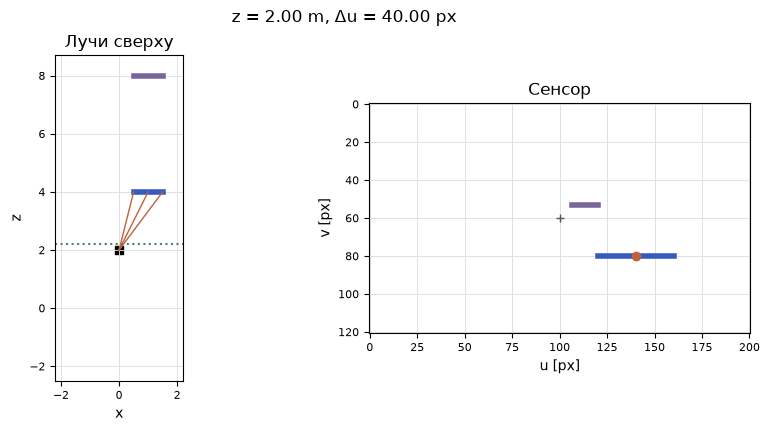

In [7]:
fig = demos.perspective_figure("ru", camera_z=2)
plt.show()

In [8]:
K = np.array([[80, 0, 100], [0, 80, 60], [0, 0, 1]])
h = K @ p
print("Kp =", h, "   (u, v) =", h[:2]/h[2])
for z in [4, 8]:
    print(f"z={z}: move → {80/(z-2):.2f} px; zoom → {160/z:.2f} px")

Kp = [480. 280.   4.]    (u, v) = [120.  70.]
z=4: move → 40.00 px; zoom → 40.00 px
z=8: move → 13.33 px; zoom → 20.00 px


## 8. Два кадра с одинаковым передним планом

Сравним сразу три кадра на одной шкале. Исходная синяя перекладина занимает 20 пиксельных интервалов. На втором кадре камера подъехала, и глубина уменьшилась с 4 до 2 м. На третьем расстояние прежнее, зато фокус стал 160 пикселей. Во втором и третьем кадре не только ширина, но и обе экранные координаты центра синей перекладины совпали. На сколько бы точек мы ни разбили именно эту переднюю плоскость, она совпадёт целиком. Для неё множитель $f/z$ в обоих случаях равен 40 пикселям на метр.

А теперь задний план. Для фиолетовой перекладины этот множитель был $80/8=10$, после движения камеры стал $80/(8-2)\approx13.33$, а при смене фокуса — $160/8=20$. Отношение ширин передней и дальней перекладин сначала было $20/10=2$. После движения получилось $40/13.33\approx3$. При смене фокуса вышло $40/20=2$, как в исходном кадре. Приближение камеры сильнее растягивает близкий предмет. Смена фокуса растягивает оба на один коэффициент относительно главной точки. Поэтому в опыте с одним предметом на одной глубине легко неверно угадать причину увеличения. Здесь для проверки есть вторая перекладина.

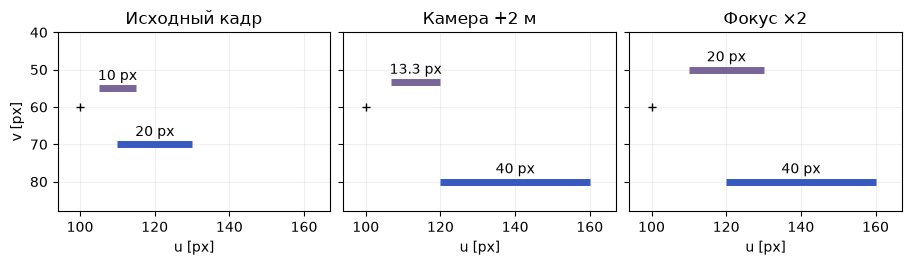

In [9]:
fig, panels = plt.subplots(1, 3, figsize=(9, 3.0), sharex=True, sharey=True, layout="constrained")
titles = ["Исходный кадр", "Камера +2 м", "Фокус ×2"]
for ax, title, (focal, advance) in zip(panels,titles,[(80,0),(80,2),(160,0)]):
    for y, z, color in [(.5,4,demos.BLUE), (-.5,8,"#796597")]:
        ends = np.array([geo.project_point([x,y,z-advance], focal, (100,60)) for x in [.5,1.5]])
        ax.plot(*ends.T, color=color, lw=5, solid_capstyle="butt")
        width = ends[1,0]-ends[0,0]
        label = f"{width:.1f}".rstrip("0").rstrip(".") + " px"
        ax.annotate(label, ends.mean(0), xytext=(0,6), textcoords="offset points", ha="center")
    ax.plot(100,60,"+", color="black")
    ax.set(xlim=(94,167), ylim=(88,40), aspect="equal", title=title, xlabel="u [px]")
    ax.grid(alpha=.2)
panels[0].set_ylabel("v [px]")
plt.show()

## 9. Два способа потерять точку

Пусть $z=0.5$ м и $x=1$ м. Луч ещё смотрит вперёд, но $u=100+80/0.5=260$ уже за правым краем. При $z=0.2$ срабатывает другое правило: в этой сцене мы сохраняем только глубины **строго больше** 0.2 м. Ближняя плоскость защищает от огромных значений вблизи деления на ноль. Для сегмента с концами по разные стороны плоскости нужна геометрическая отсечка. Наша перекладина параллельна сенсору, поэтому оба конца проходят проверку вместе.

**Опыт.** Пиксель $(120,70)$ и фокус 80 известны, глубина потерялась. Какие две разные точки могли его дать?

<details>
<summary>Разбор</summary>

Из адреса вычитается главная точка $(100,60)$. Получается $(20,10)$. Деление на 80 даёт направление $(0.25,0.125,1)$. Умножение на произвольную положительную глубину восстанавливает точку луча. Глубины 2 и 4 дают $(0.5,0.25,2)$ и $(1,0.5,4)$ м.

</details>

**Проверка на краю.** При $f_x=80$ и $z=4$ какой мировой $x$ попадёт точно в центр последнего столбца?

<details>
<summary>Разбор</summary>

Камера в начале мира, оси совпадают. Последний столбец имеет $u=200$. Смещение от середины $200-100=100$ px. Отношение $x/z=100/80=1.25$. Значит, $x=4\cdot1.25=5$ м. Самый край сенсора проходит ещё на половину пикселя правее центра этого столбца.

</details>

Соглашение о матрице $K$ и переходе из мира в камеру совпадает с записью в [описании модели камеры OpenCV](https://docs.opencv.org/4.x/d9/d0c/group__calib3d.html).

## 10. Как вернуть глубину к пикселю

Один адрес даёт два отношения, $x/z$ и $y/z$. В адресе нет отдельного измерения $z$. Два разных дополнения к опыту помогут его восстановить. В первом известна длина перекладины. Она лежит параллельно сенсору, её проекция заняла 20 пиксельных интервалов, в мире между концами ровно метр. Выше мы получили $\Delta u=f_x L/z$, где $L$ — горизонтальный размер в метрах. Умножим обе стороны на $z$, затем разделим на ненулевую $\Delta u$. Выходит $z=f_x L/\Delta u=80\cdot1/20=4$ м. Если предмет наклонён так, что его концы оказались на разных глубинах, делить на одну глубину уже нельзя. Измеренная ширина картинки сама по себе нового угла нам не сообщает.

Во втором опыте размер предмета неизвестен. Есть ещё одна камера. Она сдвинута вправо ровно на $0.8$ м, оси параллельны, фокус и главная точка те же. В первой камере середина перекладины находилась на $x=1$ м. Во второй от её начала остаётся $1-0.8=0.2$ м вправо. При глубине 4 м это даёт адрес $100+80\cdot0.2/4=104$. Первый адрес был 120. Разность $d=120-104=16$ пикселей называется **диспаратностью**. Горизонтальный перенос камер называют базой, здесь $b=0.8$ м. При вычитании главные точки сократились, и неизвестный мировой $x$ тоже исчез:

$$
\begin{aligned}
u_L-u_R
&=\left(c_x+f_x\frac{x}{z}\right)-
  \left(c_x+f_x\frac{x-b}{z}\right)\\
&=\frac{f_x}{z}\bigl(x-(x-b)\bigr)
=\frac{f_x b}{z}.
\end{aligned}
$$

Теперь $z=f_x b/d=80\cdot0.8/16=4$ м. Знаменатель должен быть положительным для этой расстановки и этого порядка вычитания. При нулевой базе разность обнуляется на любой глубине: ещё один кадр с того же места новой информации не дал. На очень далёком предмете разность мала и ошибка на один пиксель стоит дорого. При $d=4$ глубина равна $64/4=16$ м, а при $d=3$ уже $64/3\approx21.33$ м. В обоих кадрах предстоит найти **ту же самую** деталь, поэтому красивый, но ложный матч даст совершенно уверенное число для чужого луча.

**Два пиксельных шага.** У точки $(1,0.5,4)$ получился адрес $(120,72.5)$. Главная точка $(100,60)$. Какими могли быть горизонтальный и вертикальный фокусы?

<details>
<summary>Разбор</summary>

Горизонтальный сдвиг 20 px делится на $1/4$, выходит 80 px. Вертикальный сдвиг 12.5 px делится на $0.5/4$, выходит 100 px. При разном шаге сетки это могут быть числа для одного физического объектива. По одной осевой точке таким способом фокус не восстановить.
</details>

**Обрезанный кадр.** После обрезки главную точку ошибочно оставили в $(100,60)$. Где предсказание окажется относительно правильной отметки?

<details>
<summary>Разбор</summary>

Относительный сдвиг $20,10$ не изменился. Ошибочная камера предскажет $(120,70)$ в новом массиве, тогда как отметка теперь в $(90,60)$. Ошибка ровно 30 столбцов вправо и 10 строк вниз, одинаковая и для других точек. При ошибке фокуса сдвиг зависел бы от положения в кадре.
</details>

**Проверка глубины.** У дальней метки разность столбцов равна 8. Во второй камере отметку случайно выбрали на один столбец правее. В какую сторону сдвинется восстановленная глубина?

<details>
<summary>Разбор</summary>

Правый адрес вырос на единицу, поэтому из прежней разности 8 остаётся 7. Вместо $64/8=8$ м получится $64/7\approx9.14$ м. Предмет кажется дальше. Поменялся единственный адрес, а обе формулы камеры остались прежними.
</details>